In [1]:
%load_ext autoreload
%autoreload 2

from comcatalyst.benchmark.analyze_results import *

# **Load results.**

In [10]:
# load from json
res = load_results_from_dir("../../data/xpr_cocabo/xpr_cocabo_case03_bo50")

In [11]:
# restrict
res = [r for r in res if r["hyperparams"]["seed"]<10]

In [12]:
# restrict number of points
res = slice_results_at_n_points(results=res, n_points=35)

In [4]:
# check
print("Total runs:", len(res))
for h in res[0]["hyperparams"]:
    values = sorted(set(r["hyperparams"][h] for r in res))
    print(f"{h:<27}: {'':>1}{values}")

Total runs: 160
seed                       :  [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
seed_ydoe_offset           :  [1000]
n_init                     :  [2, 6, 10, 14]
n_iter_bo                  :  [36, 40, 44, 48]
sampling_method            :  ['LHS']
sampling_criterion         :  ['ese']
acq_type                   :  ['EI', 'LCB']
kernel_mix                 :  [0.5]
sigma_noise                :  [0.1, 0.5]


# **Plot results.**

## **Convergence curve.**

In [ ]:
for n_init in [2, 6, 10, 14]:
    for sigma_noise in [0.1, 0.5]:
        for acq_type in ["EI", "LCB"]:
                print(f"n_init={n_init}, sigma_noise={sigma_noise}, acq_type={acq_type}")
                plot_convergence_curve(
                    results=res,
                    metric="y_true_at_x_data",
                    filters={
                        "n_init": n_init,
                        "sigma_noise": sigma_noise,
                        "acq_type": acq_type,
                    },
                    figsize=(9,5),
                    vline=30,
                    fontsize=12
                )

## **Boxplots.**

### **Boxplots _y_ by n\_init.**

sigma_noise=0.1, acq_type=EI


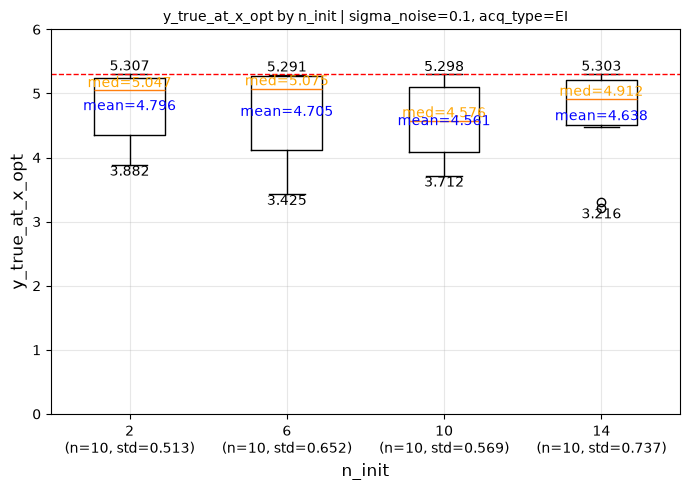

sigma_noise=0.1, acq_type=LCB


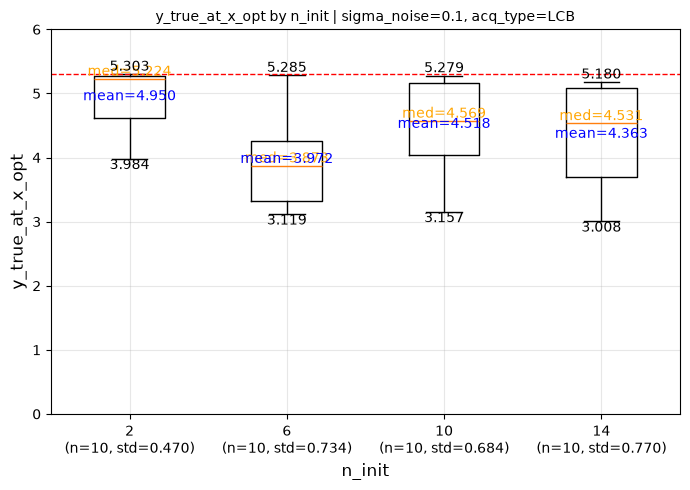

sigma_noise=0.5, acq_type=EI


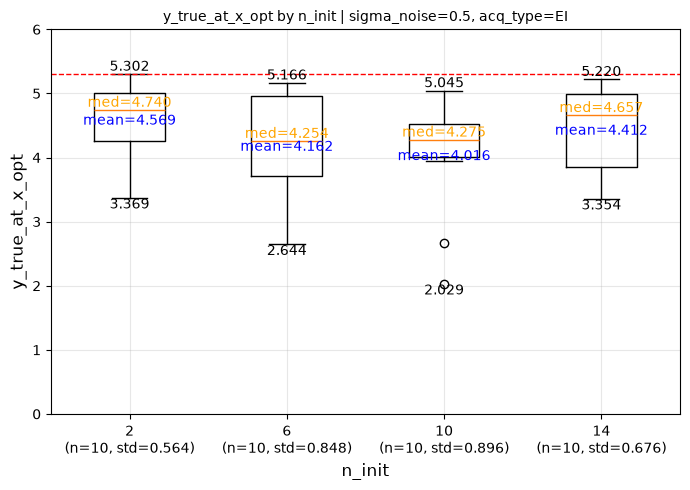

sigma_noise=0.5, acq_type=LCB


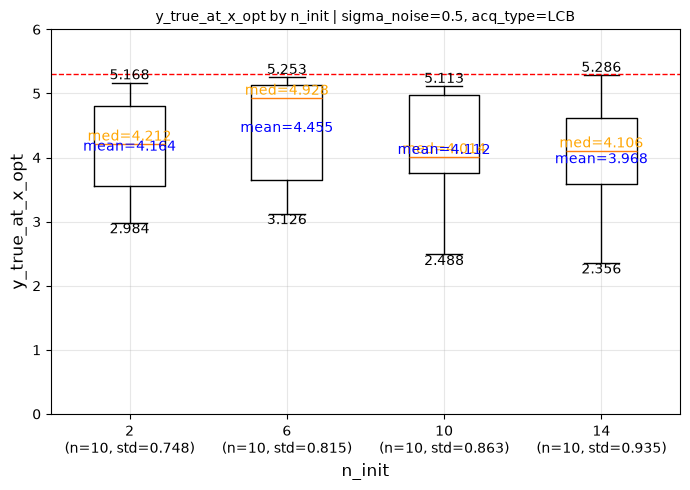

In [13]:
# y by n_init
for sigma_noise in [0.1, 0.5]:
    for acq_type in ["EI", "LCB"]:
            print(f"sigma_noise={sigma_noise}, acq_type={acq_type}")
            plot_boxplot(
                results=res,
                metric="y_true_at_x_opt",
                group_by="n_init",
                filters={
                    "sigma_noise": sigma_noise,
                    "acq_type": acq_type,
                },
                ylim=(0,6),
                fontsize=12
            )

### **Boxplots _y_ by sigma\_noise.**

n_init=2, acq_type=EI


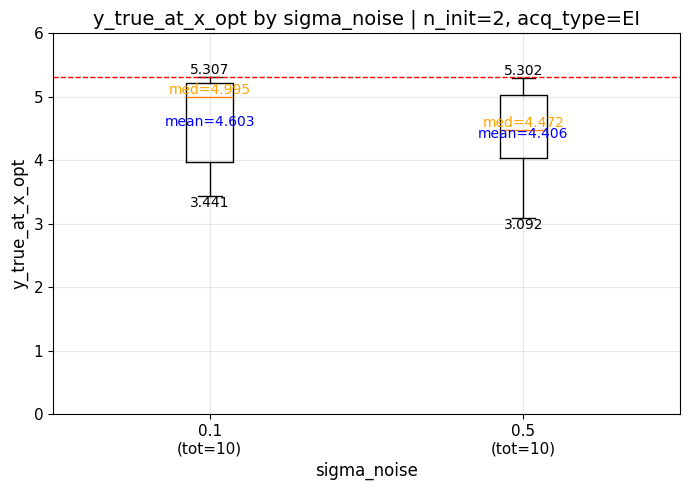

n_init=2, acq_type=LCB


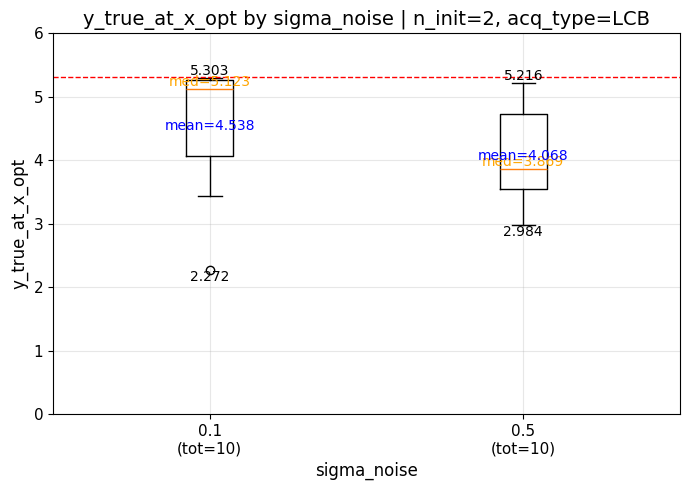

n_init=6, acq_type=EI


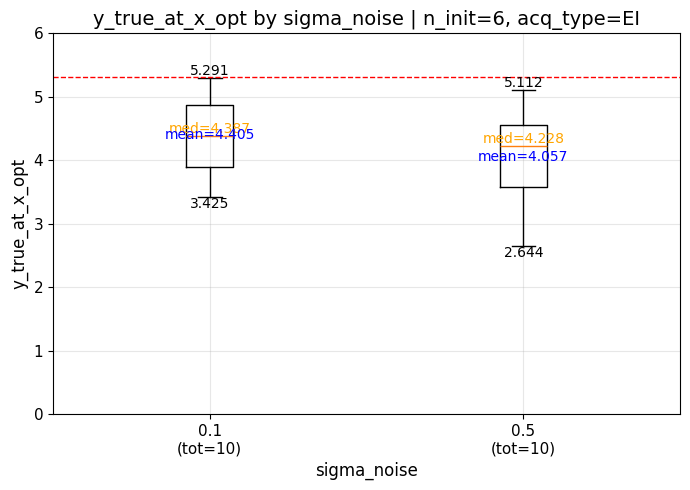

n_init=6, acq_type=LCB


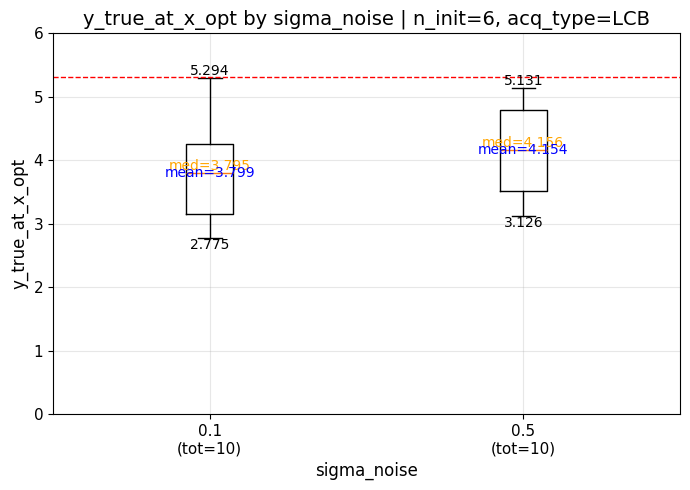

n_init=10, acq_type=EI


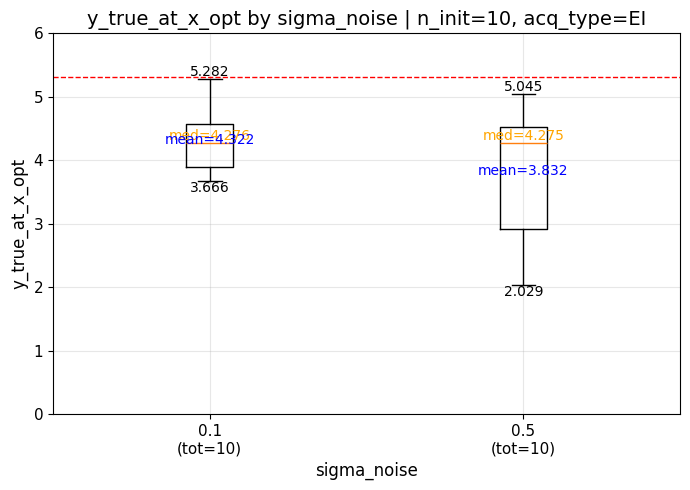

n_init=10, acq_type=LCB


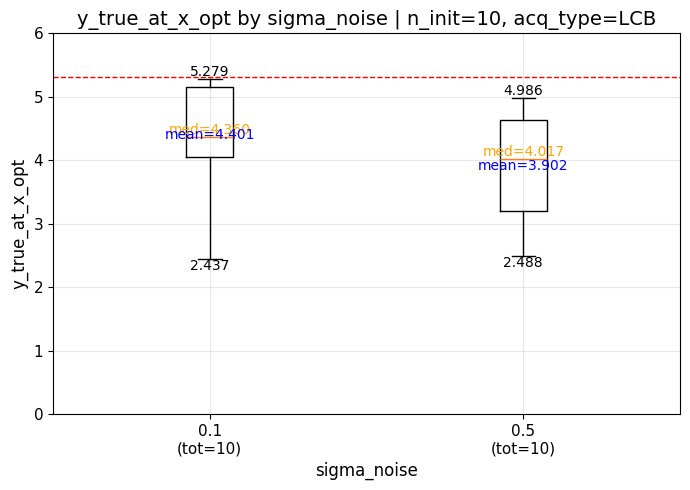

n_init=14, acq_type=EI


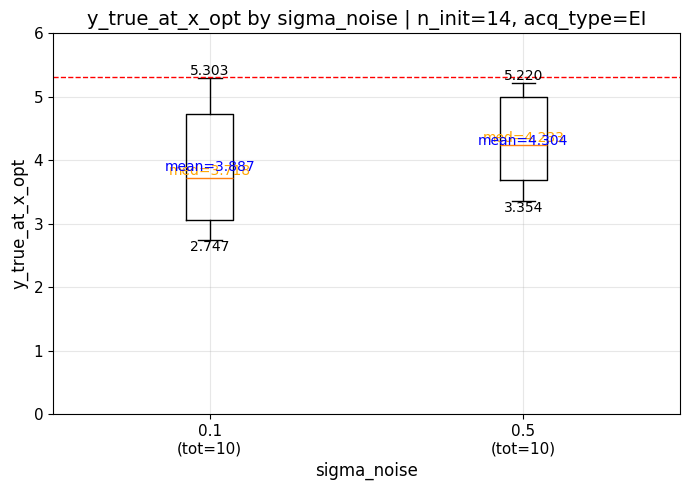

n_init=14, acq_type=LCB


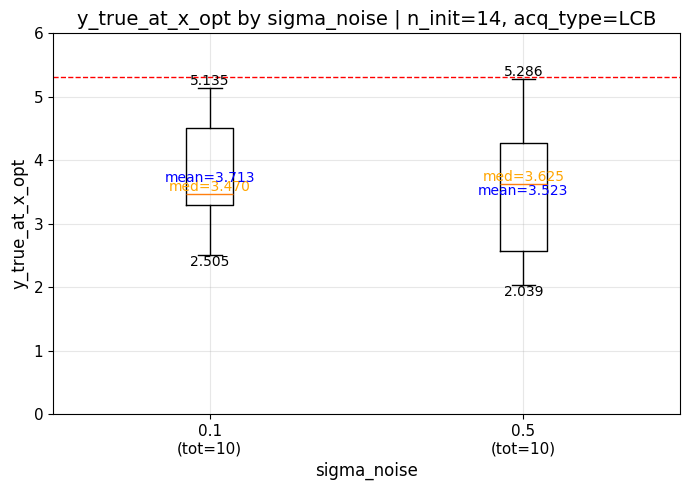

In [23]:
# y by sigma_noise
for n_init in [2, 6, 10, 14]:
    for acq_type in ["EI", "LCB"]:
            print(f"n_init={n_init}, acq_type={acq_type}")
            plot_boxplot(
                results=res,
                metric="y_true_at_x_opt",
                group_by="sigma_noise",
                filters={
                    "n_init": n_init,
                    "acq_type": acq_type,
                },
                ylim=(0,6),
                fontsize=12
            )

### **Boxplots _y_ by acq\_type.**

In [ ]:
# y by sigma_noise
for n_init in [2, 6, 10, 14]:
    for sigma_noise in [0.1, 0.5]:
            print(f"n_init={n_init}, sigma_noise={sigma_noise}")
            plot_boxplot(
                results=res,
                metric="y_true_at_x_opt",
                group_by="acq_type",
                filters={
                    "n_init": n_init,
                    "sigma_noise": sigma_noise,
                },
                ylim=(0,6),
                fontsize=12
            )

# **Investigate results.**

In [24]:
from comcatalyst.context.cases import case_03
vars_metadata = case_03().vars_metadata

In [33]:
summarize_results(
    results=res, 
    vars_metadata=vars_metadata, 
    epsilon=0.5,
    filters={"n_init": 6, "sigma_noise": 0.1, "acq_type": "EI"},
)

N runs=10

y_opt mean=4.474, std=0.664, min=3.4262, max=5.4455
y_true_at_x_opt mean=4.405, std=0.607, min=3.4254, max=5.2909

Success rate gap=0.5: 3/10=30.0%

Correlation y_true_at_x_opt vs y_init_max: -0.228
Correlation y_true_at_x_opt vs n correct combo in init: -0.014
Correlation y_true_at_x_opt vs n 'c1=0' in init: 0.153
Correlation y_true_at_x_opt vs n 'c2=0' in init: 0.227
Correlation y_true_at_x_opt vs dist best init to x_true_max: -0.452
Correlation y_true_at_x_opt vs mean abs noise: 0.589


In [44]:
stats_bo_errors(
    results=res, 
    vars_metadata=vars_metadata,
    filters={"n_init": 6, "sigma_noise": 0.1, "acq_type": "EI"}
)

N runs=10

Prop correct combo of x_opt                               : 0.600
Mean quant dist to x_true_max for correct combo of x_opt  : 0.33104957266793694
Std quant dist to x_true_max for correct combo of x_opt   : 0.21139866861283707
Mean quant dist to x_true_max for wrong combo of x_opt    : 0.750256012638062
Std quant dist to x_true_max for wrong combo of x_opt     : 0.13249843797881936
Prop x_opt in x_init                                      : 0.000


In [40]:
stats_x_opt_qual_combos(
    results=res,
    vars_metadata=vars_metadata,
    metric="y_true_at_x_opt",
    metric_range=(-20, 20),
    filters={"n_init": 6, "sigma_noise": 0.1, "acq_type": "EI"},
)


10 runs with y_true_at_x_opt in [-20, 20]

Combo                   n       %
-----------------------------------
A/alpha                 6    60.0%
A/lambda                3    30.0%
A/phi                   1    10.0%


In [39]:
stats_seed_variance(
    results=res,
    metric="y_true_at_x_opt",
    filters={"n_init": 6, "sigma_noise": 0.1},
)

N seeds=10, N runs=20

Variance intra-seed (hyperparams)   : 0.2588
Variance inter-seed (plan initial)  : 0.3488
Ratio inter/intra                   : 1.348


In [ ]:
plot_boxplot_by_seed(
    results = res,
    metric  = "y_true_at_x_opt",
    filters={"n_init": 6, "sigma_noise": 0.1, "acq_type": "EI"},
)

In [ ]:
details_doe_by_metric_range(
    results=res,
    vars_metadata=vars_metadata,
    metric="y_true_at_x_opt",
    metric_range=(-10, 10),
    top_k=5,
    filters={"n_init": 6, "sigma_noise": 0.1, "acq_type": "EI"},
)